## **Business Problem Understanding**

An experiment was conducted on 5000 participants to study the effects of age and physical health on hearing loss, specifically the ability to hear high pitched tones. This data displays the result of the study in which participants were evaluated and scored for physical ability and then had to take an audio test (pass/no pass) which evaluated their ability to hear high frequencies. The age of the user was also noted. Is it possible to build a model that would predict someone's llikelyhood  to hear the high frequency sound based solely on their features (age and physical score)?

In [4]:
import sys

!{sys.executable} -m pip install seaborn

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

#print("Seaborn:", sns.__version__)
print("All imports successful!")

All imports successful!


In [6]:
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as  plt
%matplotlib inline
import warnings
warnings.simplefilter('ignore')

In [7]:
df = pd.read_csv('hearing_test.csv')
df.head()

,age,physical_score,test_result
0,33.0,40.7,1
1,50.0,37.2,1
2,52.0,24.7,0
3,56.0,31.0,0
4,35.0,42.9,1


## **Data Understanding**

- Features
    - age - Age of participent in years
    - physical_score - Score achieved during physical exam

- Label/ Targe
    - test_result - 0 if no pass, 1 if test passed

    

## Dataset Understanding

In [8]:
df.shape

(5000, 3)

In [9]:
df.columns


Index(['age', 'physical_score', 'test_result'], dtype='str')

In [10]:
df.dtypes

age               float64
physical_score    float64
test_result         int64
dtype: object

In [11]:
df.test_result.value_counts()

test_result
1    3000
0    2000
Name: count, dtype: int64

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             5000 non-null   float64
 1   physical_score  5000 non-null   float64
 2   test_result     5000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 117.3 KB


## **Exploratory Data Analysis and Visualization**

Feel free to explore the data further on your own.

In [13]:
df.describe()

,age,physical_score,test_result
count,5000.000000,5000.000000,5000.000000
mean,51.609000,32.760260,0.600000
std,11.287001,8.169802,0.489947
min,18.000000,-0.000000,0.000000
25%,43.000000,26.700000,0.000000
50%,51.000000,35.300000,1.000000
75%,60.000000,38.900000,1.000000
max,90.000000,50.000000,1.000000


<Axes: ylabel='age'>

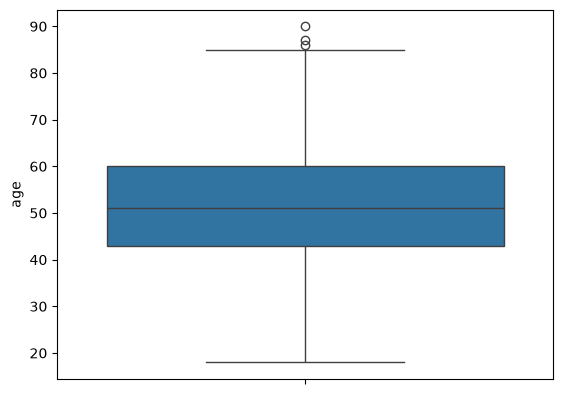

In [14]:
sns.boxplot(df['age'])

<Axes: ylabel='physical_score'>

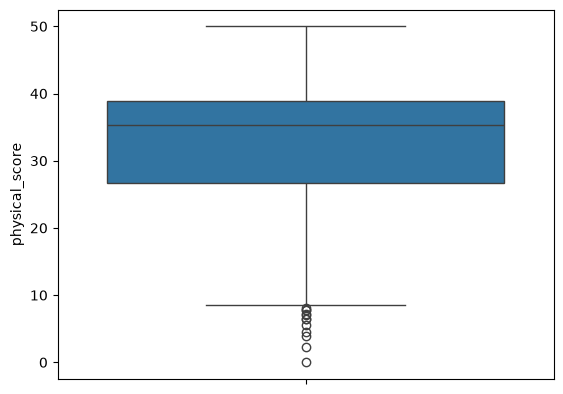

In [15]:
sns.boxplot(df.physical_score)

<Axes: ylabel='count'>

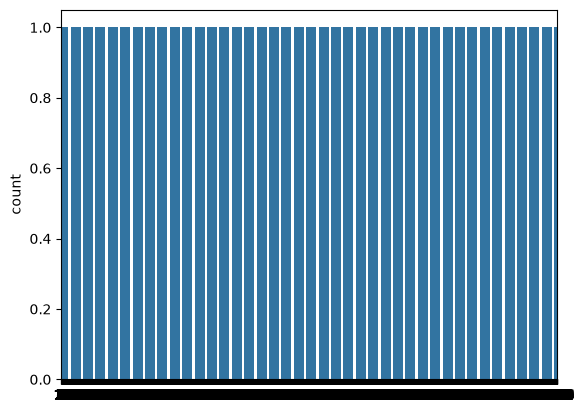

In [16]:
sns.countplot(df.test_result)

<Axes: xlabel='test_result', ylabel='count'>

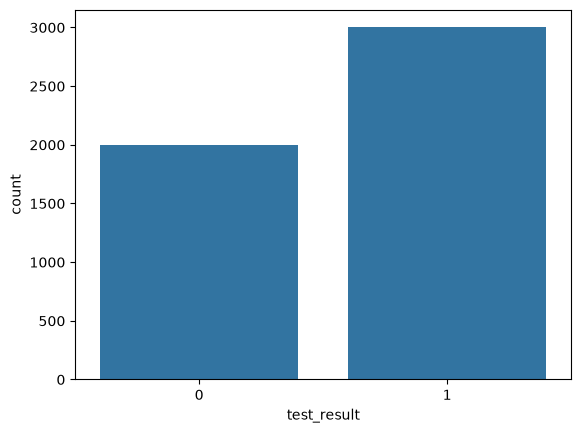

In [17]:
sns.countplot(data=df, x='test_result')

<Axes: xlabel='test_result', ylabel='age'>

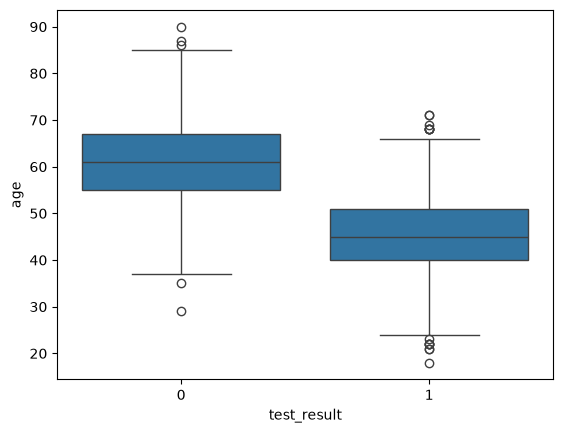

In [18]:
sns.boxplot(x='test_result', y = 'age', data = df)

<Axes: xlabel='test_result', ylabel='physical_score'>

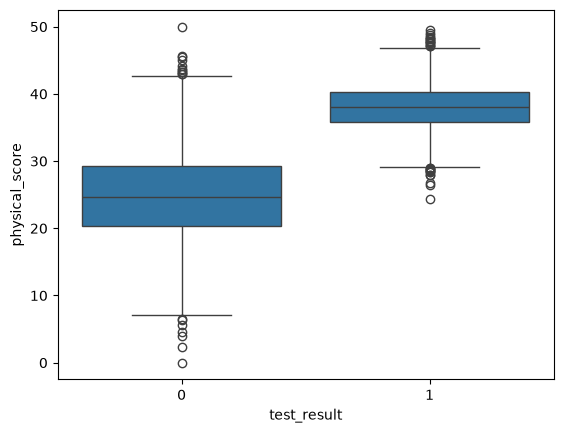

In [19]:
sns.boxplot(x='test_result', y = 'physical_score', data = df)

<Axes: xlabel='age', ylabel='physical_score'>

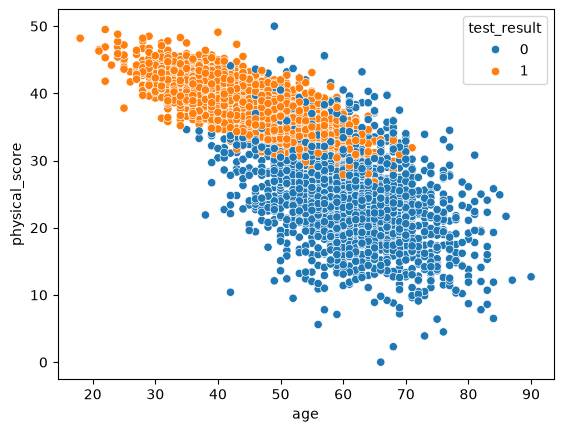

In [20]:
sns.scatterplot(x='age', y ='physical_score',data = df, hue='test_result')

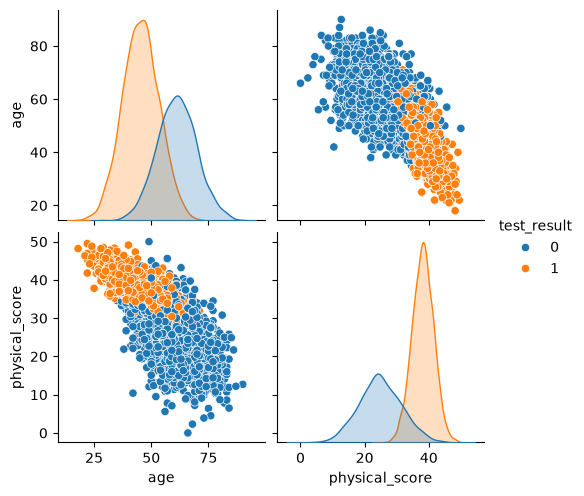

In [21]:
sns.pairplot(df, hue='test_result')

<Axes: >

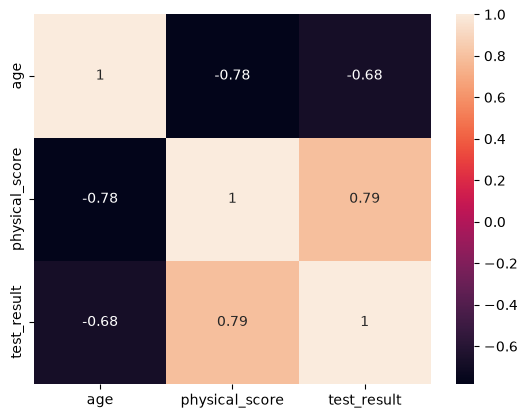

In [22]:
sns.heatmap(df.corr(), annot=True)

<Axes: xlabel='physical_score', ylabel='test_result'>

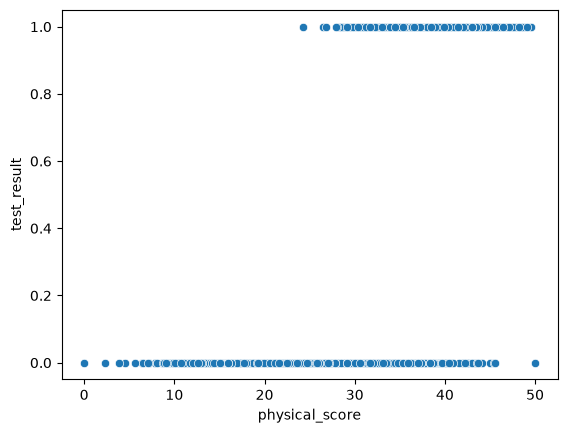

In [23]:
sns.scatterplot(x='physical_score', y ='test_result', data= df)

<Axes: xlabel='age', ylabel='test_result'>

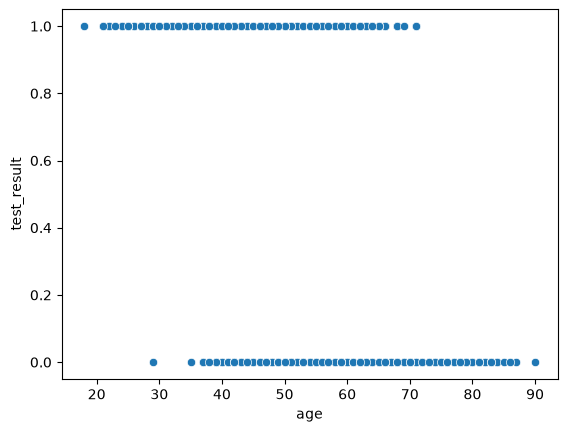

In [24]:
sns.scatterplot(x='age', y ='test_result', data= df)

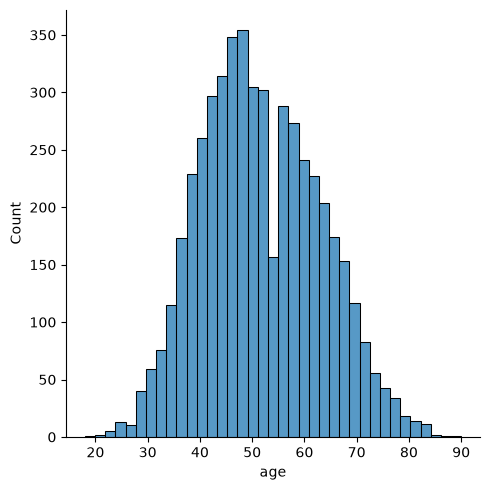

In [25]:
sns.displot(df.age)

In [26]:
df.age.skew()

np.float64(0.22094186437338634)

In [27]:
df.physical_score.skew()

np.float64(-0.7792816279520078)

In [28]:
df.isnull().sum()


age               0
physical_score    0
test_result       0
dtype: int64

### **EDA**

In [29]:
from feature_engine.outliers  import Winsorizer

win = Winsorizer(capping_method = 'iqr', variables = ['age'], tail = 'both', fold = 1.5)

df['age'] = win.fit_transform(df[['age']])

print(win.left_tail_caps_, win.right_tail_caps_)

# df.age = df.age.median()


{'age': 17.5} {'age': 85.5}


In [30]:
from feature_engine.outliers import Winsorizer 

win = Winsorizer(capping_method = 'iqr', variables=['physical_score'], tail='both', fold = 1.5)
df['physical_score'] = win.fit_transform(df[['physical_score']])
print(win.left_tail_caps_, win.right_tail_caps_)

{'physical_score': 8.399999999999999} {'physical_score': 57.20000000000001}


In [31]:
from feature_engine.outliers import Winsorizer

win= Winsorizer(capping_method='iqr',variables=['physical_score'],tail='both',fold=1.5)

df['physical_score']=win.fit_transform(df[['physical_score']])

print(win.left_tail_caps_,win.right_tail_caps_)

{'physical_score': 8.399999999999999} {'physical_score': 57.20000000000001}


#### **X & y**

In [32]:
X = df.drop('test_result', axis = 1)
y = df['test_result']

#### **Train | Test Split**

In [33]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=21,test_size=0.3)

#### **Scaling**

In [34]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_tain = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## **Modeling**

#### **Logistic Regression Model (Baseline Model or Raw Model)**

In [35]:
#import ML algorithm

from sklearn.linear_model import LogisticRegression

In [36]:
# save ML algorithm in a model

log_model = LogisticRegression()

In [37]:
# model.fit()
log_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [38]:
log_model.intercept_

array([-10.45472857])

In [39]:
log_model.coef_

array([[-0.07194756,  0.44664693]])

### **Prediction**

In [40]:
train_prediction = log_model.predict(X_train)
test_prediction = log_model.predict(X_test)

### **Evaluation**

In [41]:
from sklearn.metrics import accuracy_score

In [42]:
accuracy_score(y_train, train_prediction)   # Train accuaracy

0.9182857142857143

In [43]:
accuracy_score(y_test, test_prediction)  # Test accuracy

0.4033333333333333

In [44]:
from sklearn.metrics import confusion_matrix

In [45]:
confusion_matrix(y_test, test_prediction)

array([[605,   0],
       [895,   0]])

## Cross Validation Score

In [46]:
from sklearn.model_selection import cross_val_score

score = cross_val_score(log_model, X, y, cv = 5)
print(score)
score.mean()

[0.933 0.915 0.908 0.91  0.914]


np.float64(0.916)

## Classification report

In [47]:
from sklearn.metrics import classification_report 
print(classification_report(y_test, test_prediction))

              precision    recall  f1-score   support

           0       0.40      1.00      0.57       605
           1       0.00      0.00      0.00       895

    accuracy                           0.40      1500
   macro avg       0.20      0.50      0.29      1500
weighted avg       0.16      0.40      0.23      1500

